# Binary segmentation

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Train, evaluate and apply a U-Net model for building-footprint segmentation
</div>
<!-- markdownlint-enable MD033 -->

---

You now understand what a segmentation model predicts and how it is built. This page walks through a complete binary segmentation workflow, building footprint detection, from raw data to GIS-ready vector output. The pattern you learn here repeats, with small adaptations, across the rest of this lesson.

---

## 1. Motivation

Building footprint segmentation is a clear, well-scoped binary problem (building versus background), which makes it a good vehicle for learning the full workflow before you add the complications of multiple bands (next page) or many classes (page 7). Everything from here on is a variation on this same pattern.

---

## 2. Core idea

The workflow has a consistent shape regardless of the specific target class: acquire imagery and labels, cut them into training tiles, train a U-Net model, evaluate its performance on held-out data, run inference on new imagery, and convert the raster output into usable vector features.

```mermaid
flowchart LR
    subgraph P1 ["1. Data Preparation"]
        direction TB
        A[Imagery + Polygons] --> B[Inspect Alignment] --> C[Create Image/Mask Tiles]
    end

    subgraph P2 ["2. Model Development"]
        direction TB
        D[Train U-Net] --> E[Evaluate History]
    end

    subgraph P3 ["3. Post-Processing"]
        direction TB
        F[Run Inference] --> G[Inspect Probability Map] --> H[Vectorization]
    end

    P1 --> P2 --> P3
```

---

## 3. Workflow

### A. Download and inspect the data

In [13]:
from pathlib import Path

import geoai

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

train_raster_url = "https://data.source.coop/giuz/sds320/L07/data/willisau_2024_swissimage_rgb_subset_05m.tif"
train_vector_url = "https://data.source.coop/giuz/sds320/L07/data/willisau_2024_swissbuildings3D_clip.geojson"
test_raster_url = "https://data.source.coop/giuz/sds320/L07/data/marly_2023_swissimage_rgb_subset_05m.tif"

train_raster_path = geoai.download_file(
    train_raster_url, output_path=str(DATA_DIR / Path(train_raster_url).name)
)
train_vector_path = geoai.download_file(
    train_vector_url, output_path=str(DATA_DIR / Path(train_vector_url).name)
)
test_raster_path = geoai.download_file(
    test_raster_url, output_path=str(DATA_DIR / Path(test_raster_url).name)
)

The training data is a 0.5 m SWISSIMAGE RGB orthophoto of Willisau (2024) paired with swissBUILDINGS3D building footprint polygons. A separate SWISSIMAGE orthophoto of Marly (2023) serves as the held-out test set: a different town, captured in a different year. Both rasters are in the Swiss LV95 coordinate system (EPSG:2056).

Before training, inspect both the raster and the reference polygons.

In [14]:
geoai.print_raster_info(
    train_raster_path,
    show_preview=False,
)

===== RASTER INFORMATION: data/raw/willisau_2024_swissimage_rgb_subset_05m.tif =====
Driver: GTiff
Dimensions: 2181 x 1031 pixels
Number of bands: 3
Data type: uint8
Coordinate Reference System: EPSG:2056
Georeferenced Bounds: BoundingBox(left=2641062.19, bottom=1218339.81, right=2642152.69, top=1218855.31)
Pixel Resolution: 0.5, 0.5
NoData Value: None
----- Band Statistics -----
Band 1:
  Min: 13.00
  Max: 255.00
  Mean: 84.41
  Std Dev: 40.82
Band 2:
  Min: 13.00
  Max: 255.00
  Mean: 93.14
  Std Dev: 38.82
Band 3:
  Min: 7.00
  Max: 255.00
  Mean: 75.13
  Std Dev: 39.21


Then overlay the building footprints on the imagery.

In [15]:
import geopandas as gpd

# The swissBUILDINGS3D footprints have datetime columns (DATUM_AENDERUNG,
# DATUM_ERSTELLUNG). folium/leafmap can't serialize pandas Timestamp values
# to JSON when building the interactive popup, so convert them to strings
# before mapping.
train_vector_gdf = gpd.read_file(train_vector_path)
for col in train_vector_gdf.columns:
    if train_vector_gdf[col].dtype.kind == "M":  # datetime64, incl. timezone-aware
        train_vector_gdf[col] = train_vector_gdf[col].astype(str)

geoai.view_vector_interactive(
    train_vector_gdf,
    tiles=train_raster_path,
)

`view_vector_interactive()` overlays the building footprint polygons directly on the training imagery, letting you visually confirm the labels actually align with the buildings before you spend any time training. This is the segmentation equivalent of the annotation check you did for detection in L06, and just as important.

Expect small, systematic differences that are not labelling errors. swissBUILDINGS3D outlines are building footprints, while the orthophoto shows roofs, which usually overhang the walls. SWISSIMAGE is also not a true orthophoto, so taller buildings appear to lean away from the image centre and their roofs shift slightly relative to the footprints. Look for offsets that are larger than this or for buildings that are missing entirely.

In [16]:
geoai.view_raster(test_raster_path)

### B. Create training tiles

The large training raster is divided into overlapping patches.

In [17]:
out_folder = "buildings"

tiles = geoai.export_geotiff_tiles(
    in_raster=train_raster_path,
    out_folder=out_folder,
    in_class_data=train_vector_path,
    tile_size=512,
    stride=256,
    buffer_radius=0,
)

'class' not found in vector data. Using default class ID 1.


Generating tiles:   0%|          | 0/32 [00:00<?, ?it/s]

`export_geotiff_tiles()` slices the training raster and rasterizes the vector labels into matching 512-by-512 pixel tiles, with a 256-pixel stride creating overlap between neighboring tiles. This overlap increases the effective training set size and helps the model learn features near tile boundaries, rather than only in tile interiors.

The message `'class' not found in vector data. Using default class ID 1.` is expected: the footprints have no class column, so every building polygon is burned into the mask as class 1 and everything else stays background (0), which is exactly what a binary task needs.

### C. Train the U-Net model

In [18]:
geoai.train_segmentation_model(
    images_dir=f"{out_folder}/images",
    labels_dir=f"{out_folder}/labels",
    output_dir=f"{out_folder}/unet_models",
    architecture="unet",
    encoder_name="resnet34",
    encoder_weights="imagenet",
    num_channels=3,
    num_classes=2,
    batch_size=8,
    num_epochs=20,
    learning_rate=0.001,
    val_split=0.2,
)

`num_classes=2` reflects background and building; `num_channels=3` matches the RGB input. `encoder_weights="imagenet"` is what activates the {term}`transfer learning <Transfer Learning>` discussed on the previous page. This configuration, U-Net plus a ResNet34 encoder, is a strong default binary-segmentation baseline.

Important {term}`Hyperparameter` choices include:

- `batch_size`,
- `num_epochs`,
- `learning_rate`,
- `val_split`.

For your own project, record these settings alongside the resulting model {term}`Checkpoint`.

### D. Evaluate the model

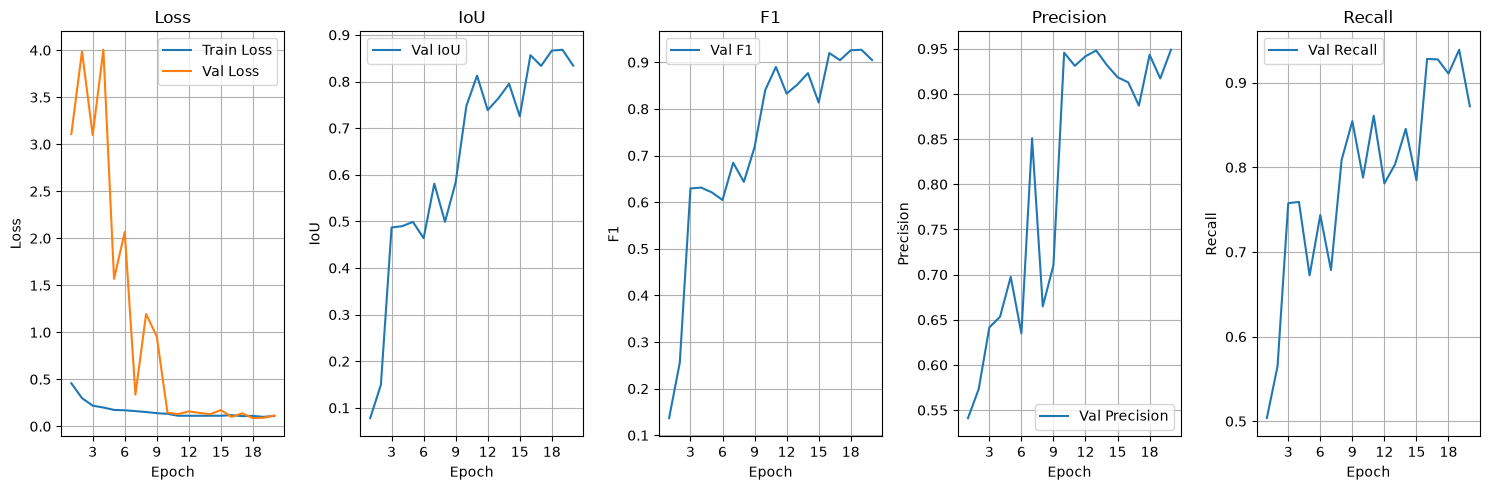

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.457681,3.108153,0.078117,0.136899,0.541224,0.503759
1,2,0.299629,3.986155,0.149350,0.255683,0.573176,0.565158
2,3,0.219580,3.097923,0.486848,0.629389,0.641646,0.757577
3,4,0.199919,4.004939,0.489779,0.631193,0.653333,0.759182
4,5,0.174328,1.568248,0.498848,0.621006,0.697507,0.672385
5,6,0.170588,2.066442,0.463917,0.604589,0.635005,0.743641
6,7,0.161679,0.336996,0.580955,0.684479,0.850964,0.678657
7,8,0.151974,1.194684,0.499115,0.643423,0.664937,0.808820
8,9,0.139575,0.956037,0.583738,0.717821,0.710408,0.854533
9,10,0.132951,0.145250,0.747404,0.840385,0.945666,0.787829


In [19]:
geoai.plot_performance_metrics(
    history_path=f"{out_folder}/unet_models/training_history.pth",
    figsize=(15, 5),
)

This plots training and validation loss alongside {term}`IoU <Intersection over Union>`, {term}`F1-score`, {term}`precision <Precision>`, and {term}`recall <Recall>` over training epochs, and prints a short summary of the best and final values for each. A healthy run shows both {term}`loss <Loss Function>` curves decreasing together, with validation loss tracking training loss closely; a growing gap between the two is the classic sign of {term}`overfitting <Overfitting>`, where the model memorizes training examples rather than learning patterns that generalize.

```{admonition} Read the gap, not just the numbers
:class: important
A final validation IoU of 0.90 sounds strong on its own, but check the loss curves too. If validation loss started rising while training loss kept falling, that 0.90 may reflect an earlier, better {term}`checkpoint <Checkpoint>` rather than the final one, which is exactly why `geoai` saves the *best* checkpoint separately from the final one.
```

```{admonition} Validation scores are optimistic here
:class: warning
The Willisau training image is small (2181 × 1031 pixels), so 512/256 tiling yields only about 20 tiles, and `val_split=0.2` holds back just a handful of them. Because neighbouring tiles overlap by 50%, every validation tile shares pixels with training tiles. The validation metrics therefore overstate how well the model generalizes. The independent check is the Marly test image in step E, a different town captured in a different year.
```

### E. Run inference

In [20]:
masks_path = "marly_buildings_prediction.tif"
probability_path = "marly_test_probability_map.tif"
model_path = f"{out_folder}/unet_models/best_model.pth"

geoai.semantic_segmentation(
    input_path=test_raster_path,
    output_path=masks_path,
    model_path=model_path,
    architecture="unet",
    encoder_name="resnet34",
    num_channels=3,
    num_classes=2,
    window_size=512,
    overlap=256,
    batch_size=4,
    probability_path=probability_path,
)

  0%|          | 0/32 [00:00<?, ?it/s]

Note that inference runs on `test_raster_path`, the held-out image the model never saw during training or validation, not on the training imagery itself. Passing `probability_path` additionally saves the per-class probability map introduced on the [pixel masks page](02_pixel-masks-and-segmentation-concepts.md), useful here for checking how confident the model is near building edges.

### F. Inspect masks and uncertainty

Display the predicted building mask over the original imagery.

In [21]:
geoai.view_raster(
    masks_path,
    nodata=0,
    colormap="binary",
    basemap=test_raster_path,
)

For the two-class model, the second probability-map band represents the building class.

In [22]:
geoai.view_raster(
    probability_path,
    indexes=[2],
    basemap=test_raster_path,
)

Inspect building edges, small structures, narrow gaps, shadows, visually similar non-building surfaces and tile-boundary regions. Intermediate probability values near boundaries can indicate locations where the class decision is less clear.

A predicted building mask can contain both types of pixel-level error.

A {term}`False Positive` occurs where background pixels are predicted as building. Potential causes include bright paved surfaces, shadows and roof-like textures or limited background variation during training.

A {term}`False Negative` occurs where real building pixels are missed. Potential causes include very small buildings, unusual roof materials, low contrast, partial occlusion, or inconsistent reference labels.

Look across several areas rather than drawing conclusions from one visually appealing example.

### G. Vectorize and filter the predictions

In [23]:
output_vector_path = "marly_buildings_prediction.geojson"

gdf = geoai.orthogonalize(
    masks_path,
    output_vector_path,
    epsilon=2,
)

gdf_props = geoai.add_geometric_properties(gdf, area_unit="m2", length_unit="m")
gdf_filtered = gdf_props[(gdf_props["area_m2"] > 10)]

geoai.create_split_map(
    left_layer=gdf_filtered,
    right_layer=test_raster_path,
    left_args={"style": {"color": "red", "fillOpacity": 0.2}},
    basemap=test_raster_path,
)

Converting features:   0%|          | 0/399 [00:00<?, ?shape/s]

Map(center=[46.7714935, 7.1649455], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title'…

{term}`Orthogonalization` converts the raw raster mask into vector polygons and regularizes their edges into clean, right-angled shapes, which better represents how buildings actually look than the slightly jagged outlines a raw raster-to-vector conversion would produce. `add_geometric_properties()` then computes area and perimeter for each polygon, which is what lets you filter out very small, likely spurious detections (`area_m2 > 10` here) before treating the output as a finished result.

---

## 4. Python reactivation

`f"{out_folder}/unet_models/best_model.pth"` is an f-string building a path by inserting a variable into a larger string, the same pattern used throughout this workflow to keep related outputs organized under one folder. `gdf_props[(gdf_props["area_m2"] > 10)]` is boolean indexing on a GeoDataFrame: the condition inside the brackets produces `True`/`False` for every row, and only the `True` rows are kept, the same filtering pattern you have used on DataFrames in earlier lessons.

---

## 5. Common pitfalls

- **Skipping the label-alignment check in step A.** Training on misaligned labels produces a model that learns a systematically wrong offset, which is easy to miss until you inspect predictions and hard to fix after the fact.
- **Forgetting `num_classes` includes background.** A binary task is `num_classes=2`, not `1`, the same convention as the detection lesson.
- **Evaluating only the summary numbers, not the loss curves.** A single best-IoU number does not tell you whether the model was still improving, had plateaued, or had already started overfitting by that point.
- **Treating the raw raster mask as the finished deliverable.** For most GIS uses, the vectorized, filtered, and orthogonalized output in step G is what you actually want to share or analyze further.

---

## 6. Mini task

Before changing any model settings, inspect the building workflow and identify:

1. one possible source of false-positive building pixels,
2. one possible source of false-negative pixels,
3. one reason the 512/256 tiling strategy may help,
4. one reason a spatially separate test area is valuable.

:::{note} Sample solution
:class: dropdown

Possible answers include:

1. **False positive:** a bright paved structure or roof-like texture is predicted as building.
2. **False negative:** a small or unusual roof is missed.
3. **Overlap:** a building close to one tile edge appears more centrally in another overlapping tile.
4. **Spatial test area:** it checks whether the model transfers beyond the exact spatial patterns present in training.

:::

---

## 7. Key takeaways

- The core segmentation workflow, tiles, train, evaluate, infer, vectorize, stays the same across binary tasks; only the specific class and data change.
- `num_classes=2` for binary segmentation includes background as one of the two classes.
- A widening gap between training and validation loss signals overfitting; `geoai` addresses this by saving the best checkpoint separately from the final one.
- Orthogonalization and geometric-property filtering turn a raw raster mask into a clean, GIS-ready vector deliverable.
- Always run inference and evaluation on held-out imagery the model never saw during training.

### Further reading

- OpenGeoAI, ["Train Segmentation Model"](https://opengeoai.org/examples/train_segmentation_model/) — the full, runnable notebook this workflow is adapted from (it uses NAIP imagery from the United States instead of SWISSIMAGE).
- SpaceNet, [news and resources](https://spacenet.ai/news-resources/) — background on one of the best-known building-footprint benchmark programs in remote sensing, useful if you want additional building-segmentation data for a project.
- [GeoAI Tutorial 19: Train a Segmentation Model for Object Detection from Remote Sensing Imagery](https://youtu.be/l8DY166eAWI) — a video walkthrough covering a similar end-to-end workflow.